# Elastic Net

Ridge and Lasso combined. The penalty is a blend controlled by `l1_ratio`:

```
1/(2n)‖y − Xw‖²  +  α·l1_ratio·‖w‖₁  +  ½·α·(1 − l1_ratio)·‖w‖²
```

- `l1_ratio=1` → Lasso (`02_ridge_lasso`), `l1_ratio=0` → Ridge.
- The L1 part still zeroes out weak features.
- The L2 part keeps **correlated features together** instead of arbitrarily picking one — Lasso's main weakness.

Same coordinate-descent solver as Lasso; the only change is the L2 term added to the update's denominator. Standardize features first if scales differ.

## Usage

```python
# (the class is defined in the Implementation section below)

model = ElasticNet(alpha=1.0, l1_ratio=0.5).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class ElasticNet:
    """Least squares + a mix of L1 and L2 penalties (scikit-learn's convention):

        1/(2n) * ||y - Xw||^2  +  alpha * l1_ratio * ||w||_1  +  0.5 * alpha * (1 - l1_ratio) * ||w||^2

    l1_ratio=1 is Lasso, l1_ratio=0 is Ridge. Solved by cyclic coordinate descent.
    The bias is not penalized (data is centered, bias recovered from the means)."""

    def __init__(self, alpha=1.0, l1_ratio=0.5, max_iter=1000, tol=1e-8):
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        x_mean, y_mean = X.mean(axis=0), y.mean()
        Xc, yc = X - x_mean, y - y_mean
        n, d = Xc.shape
        col_sq = (Xc**2).sum(axis=0)
        l1 = n * self.alpha * self.l1_ratio
        l2 = n * self.alpha * (1 - self.l1_ratio)

        w = np.zeros(d)
        residual = yc.copy()  # yc - Xc @ w, kept up to date incrementally
        for _ in range(self.max_iter):
            max_change = 0.0
            for j in range(d):
                if col_sq[j] == 0:
                    continue
                old = w[j]
                rho = Xc[:, j] @ residual + col_sq[j] * old  # correlation with residual excluding j
                # soft-threshold by the L1 part; the L2 part just inflates the denominator
                w[j] = np.sign(rho) * max(abs(rho) - l1, 0.0) / (col_sq[j] + l2)
                residual -= Xc[:, j] * (w[j] - old)
                max_change = max(max_change, abs(w[j] - old))
            if max_change < self.tol:
                break

        self.weights = w
        self.bias = y_mean - x_mean @ w
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias

## See it work

### 1. Correlated features: lasso picks one, elastic net shares

Three nearly identical copies of the same signal plus noise features. Lasso tends to keep a single copy and zero the others (which one is arbitrary). Elastic net's L2 part makes the copies share the weight.

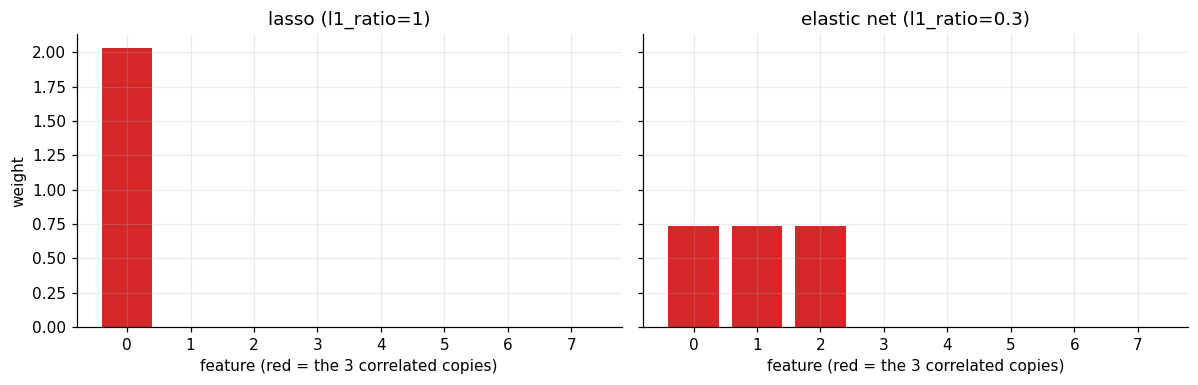

In [3]:
rng = np.random.default_rng(0)
signal = rng.normal(size=300)
X = np.column_stack([signal + 0.01 * rng.normal(size=300) for _ in range(3)] + [rng.normal(size=300) for _ in range(5)])
y = 3 * signal + rng.normal(scale=0.5, size=300)

models = {"lasso (l1_ratio=1)": ElasticNet(alpha=1.0, l1_ratio=1.0), "elastic net (l1_ratio=0.3)": ElasticNet(alpha=1.0, l1_ratio=0.3)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    m.fit(X, y); ax.bar(range(8), m.weights, color=["C3"] * 3 + ["C0"] * 5)
    ax.set(title=name, xlabel="feature (red = the 3 correlated copies)", xticks=range(8))
axes[0].set_ylabel("weight")
plt.tight_layout(); plt.show()

### 2. The mixing knob `l1_ratio`

`l1_ratio = 1` is pure lasso, `0` is (almost) pure ridge. In between you trade sparsity against stability. Number of non-zero weights as the mix changes:

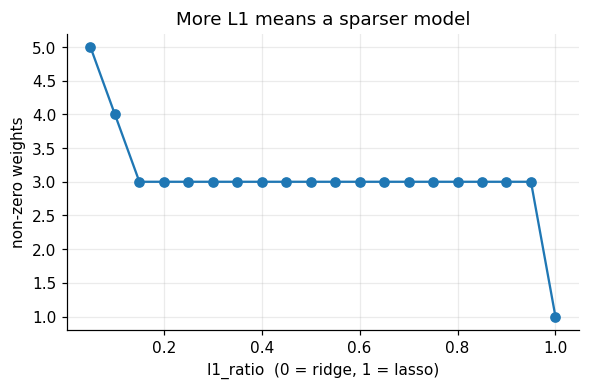

In [4]:
ratios = np.linspace(0.05, 1.0, 20)
nonzero = [(ElasticNet(alpha=1.0, l1_ratio=r).fit(X, y).weights != 0).sum() for r in ratios]
plt.figure(figsize=(6, 3.5)); plt.plot(ratios, nonzero, "o-")
plt.xlabel("l1_ratio  (0 = ridge, 1 = lasso)"); plt.ylabel("non-zero weights"); plt.title("More L1 means a sparser model"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.linear_model import ElasticNet as SklearnElasticNet

X, y = make_regression(n_samples=200, n_features=10, n_informative=4, noise=5.0, random_state=0)

ours = ElasticNet(alpha=1.0, l1_ratio=0.5).fit(X, y)
theirs = SklearnElasticNet(alpha=1.0, l1_ratio=0.5, tol=1e-10, max_iter=100000).fit(X, y)

np.set_printoptions(precision=2, suppress=True, linewidth=120)
print("ours   :", ours.weights)
print("sklearn:", theirs.coef_)
print("zeroed %d of 10 features" % (ours.weights == 0).sum())

assert np.allclose(ours.weights, theirs.coef_, atol=1e-4)
assert np.allclose(ours.bias, theirs.intercept_, atol=1e-4)

ours   : [36.12 25.84  0.66  5.67  0.    0.34 -0.33 25.58  0.02  0.62]
sklearn: [36.12 25.84  0.66  5.67  0.    0.34 -0.33 25.58  0.02  0.62]
zeroed 1 of 10 features


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def _data():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(200, 6))
    true_w = np.array([4.0, -3.0, 2.0, 0.0, 0.0, 0.0])
    y = X @ true_w + 5.0 + rng.normal(scale=0.5, size=200)
    return X, y, true_w


def test_l1_ratio_one_zeroes_irrelevant_features_like_lasso():
    X, y, true_w = _data()
    model = ElasticNet(alpha=0.1, l1_ratio=1.0).fit(X, y)
    assert (model.weights[3:] == 0).all()
    assert np.allclose(model.weights[:3], true_w[:3], atol=0.3)


def test_l1_ratio_zero_matches_ridge_closed_form():
    X, y, _ = _data()
    n, alpha = len(X), 0.3
    model = ElasticNet(alpha=alpha, l1_ratio=0.0).fit(X, y)

    Xc, yc = X - X.mean(axis=0), y - y.mean()
    ridge_w = np.linalg.solve(Xc.T @ Xc + n * alpha * np.eye(6), Xc.T @ yc)  # same objective, ridge form
    assert np.allclose(model.weights, ridge_w, atol=1e-6)


def test_keeps_correlated_features_together():
    # two near-copies of the same signal: pure L1 tends to pick one, the L2 part shares the weight
    rng = np.random.default_rng(1)
    base = rng.normal(size=300)
    X = np.column_stack([base, base + rng.normal(scale=0.01, size=300), rng.normal(size=300)])
    y = 3 * base + rng.normal(scale=0.1, size=300)
    w = ElasticNet(alpha=0.05, l1_ratio=0.3).fit(X, y).weights
    assert w[0] > 0.5 and w[1] > 0.5
    assert abs(w[0] - w[1]) < 0.3

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_l1_ratio_one_zeroes_irrelevant_features_like_lasso
PASS test_l1_ratio_zero_matches_ridge_closed_form
PASS test_keeps_correlated_features_together

all 3 tests passed


## Takeaways

- **Use it when** you have many, possibly correlated features and want some sparsity *and* stability. It is the safe default between ridge and lasso; tune `alpha` and `l1_ratio` by cross-validation.
- **Objective:** `MSE/2 + α·(l1_ratio·‖w‖₁ + (1 − l1_ratio)/2·‖w‖²)`, solved by coordinate descent with a soft-threshold and an extra L2 shrink factor in the denominator.
- **Interview line:** *"Elastic net = lasso + ridge: it keeps lasso's sparsity but, thanks to the L2 term, groups correlated features instead of picking one at random."*